In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [8]:

df = pd.read_csv("student_learning.csv")
print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
0,7.5,54,0,5.6,video,48,0
1,4.4,61,0,6.0,video,50,0
2,8.2,63,1,5.2,group,73,1
3,6.8,64,1,8.4,self,53,0
4,1.3,79,5,5.8,self,51,0


In [9]:
print("Dataset Shape:")
print(df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nTarget Balance:")
print(df["passed"].value_counts())
print("\nTarget Balance Percentage:")
print(df["passed"].value_counts(normalize=True) * 100)


Dataset Shape:
(280, 7)

Column Names:
['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method', 'final_score', 'passed']

Data Types:
hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method          str
final_score         int64
passed              int64
dtype: object

Missing Values:
hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64

Target Balance:
passed
0    157
1    123
Name: count, dtype: int64

Target Balance Percentage:
passed
0    56.071429
1    43.928571
Name: proportion, dtype: float64


In [10]:
y = df["passed"]
# Remove target and final_score from features
X = df.drop(columns=["passed", "final_score"])
print("Selected Features:")
print(X.columns.tolist())
print("\nTarget Variable:")
print(y.head())
print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Selected Features:
['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']

Target Variable:
0    0
1    0
2    1
3    0
4    0
Name: passed, dtype: int64

Feature Shape: (280, 5)
Target Shape: (280,)


In [11]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))


Training Data: (224, 5)
Testing Data: (56, 5)

Training Target Distribution:
passed
0    0.5625
1    0.4375
Name: proportion, dtype: float64

Testing Target Distribution:
passed
0    0.553571
1    0.446429
Name: proportion, dtype: float64


In [15]:
#Preprocessing
#Identifing numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["number"]
).columns
categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns

#Numerical Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Categorical Preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#Combine Preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")


Numerical Features: Index(['hours_studied', 'attendance', 'practice_tests', 'sleep_hours'],
      dtype='str')
Categorical Features: Index(['study_method'], dtype='str')

Preprocessing pipeline created successfully!


In [16]:
#Baseline Model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(
        strategy="most_frequent"
    ))
])
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)
baseline_f1 = f1_score(
    y_test, baseline_predictions,
    zero_division=0
)
print("Baseline Accuracy:", baseline_accuracy)
print("Baseline F1 Score:", baseline_f1)


Baseline Accuracy: 0.5535714285714286
Baseline F1 Score: 0.0


In [17]:
#Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
print("Logistic Regression trained successfully!")
print(
    "Accuracy:",
    accuracy_score(y_test, logistic_predictions)
)
print(
    "F1 Score:",
    f1_score(y_test, logistic_predictions,
             zero_division=0)
)


Logistic Regression trained successfully!
Accuracy: 0.75
F1 Score: 0.72


In [18]:
#Random Forest Classifier
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])
random_forest_model.fit(X_train, y_train)
rf_predictions = random_forest_model.predict(X_test)
print("Random Forest trained successfully!")
print(
    "Accuracy:",
    accuracy_score(y_test, rf_predictions)
)
print(
    "F1 Score:",
    f1_score(y_test, rf_predictions,
             zero_division=0)
)


Random Forest trained successfully!
Accuracy: 0.7142857142857143
F1 Score: 0.6923076923076923


In [19]:
#Model Evaluation
models = {
    "Dummy Baseline": baseline_predictions,
    "Logistic Regression": logistic_predictions,
    "Random Forest": rf_predictions
}
results = []
for name, predictions in models.items():
    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1 Score": f1
    })
results_df = pd.DataFrame(results)
display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    )
)


,Model,Accuracy,F1 Score
1,Logistic Regression,0.750000,0.720000
2,Random Forest,0.714286,0.692308
0,Dummy Baseline,0.553571,0.000000


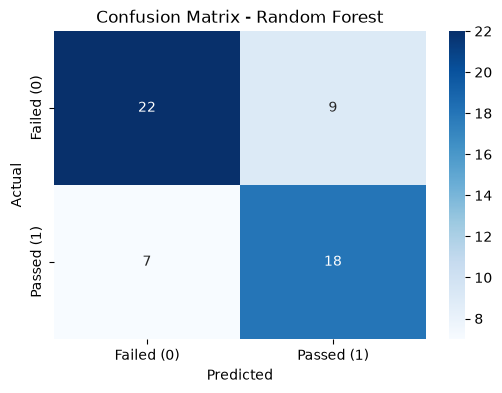


Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.71      0.73        31
           1       0.67      0.72      0.69        25

    accuracy                           0.71        56
   macro avg       0.71      0.71      0.71        56
weighted avg       0.72      0.71      0.72        56



In [20]:
#Confusion Matrix
best_predictions = rf_predictions
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Failed (0)", "Passed (1)"],
    yticklabels=["Failed (0)", "Passed (1)"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

In [22]:
#Select Best Model
trained_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}
f1_scores = {
    "Logistic Regression": f1_score(
        y_test, logistic_predictions,
        zero_division=0
    ),
    "Random Forest": f1_score(
        y_test, rf_predictions,
        zero_division=0
    )
}
best_model_name = max(
    f1_scores,
    key=f1_scores.get
)
best_model = trained_models[best_model_name]
print("Best Model:", best_model_name)
print("Best F1 Score:", f1_scores[best_model_name])


Best Model: Logistic Regression
Best F1 Score: 0.72


In [26]:
best_predictions = rf_predictions
best_predictions = best_model.predict(X_test)

In [29]:
#Saving the Best Model
#Storing the pipeline and information needed by the app

model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X.columns.tolist(),
    "numeric_features": numeric_features.tolist(),
    "categorical_features": categorical_features.tolist(),
    "numeric_defaults": X_train[numeric_features].median().to_dict(),
    "categorical_defaults": (
        X_train[categorical_features]
        .mode()
        .iloc[0]
        .to_dict()
        if not categorical_features.empty else {}
    )
}

joblib.dump(
    model_bundle,
    "best_student_model.joblib"
)
print("Best model saved successfully!")

Best model saved successfully!


In [37]:
#Model Evaluation Summary

#Importing evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

#Making predictions using the best model
best_predictions = best_model.predict(X_test)

#Calculating evaluation metrics
accuracy = accuracy_score(y_test, best_predictions)
f1 = f1_score(y_test, best_predictions)
cm = confusion_matrix(y_test, best_predictions)

#Displaying evaluation results
print("MODEL EVALUATION SUMMARY")
print("=" * 50)

print("Best Model:", best_model_name)
print("Accuracy:", round(accuracy, 4))
print("F1 Score:", round(f1, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, best_predictions))

#Responsible Use Disclaimer
disclaimer = (
    "Important: This is synthetic classroom data. Predictions are for demonstration "
    "and must not be used to judge or penalize real students."
)

print("\n" + disclaimer)

#Saving evaluation results in a text file
with open("evaluation_summary.txt", "w", encoding="utf-8") as file:

    file.write("STUDENT PASS/FAIL PREDICTION - EVALUATION SUMMARY\n")
    file.write("=" * 50 + "\n")

    file.write(f"Best Model: {best_model_name}\n")
    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"F1 Score: {f1:.4f}\n")

    file.write("\nConfusion Matrix:\n")
    file.write(str(cm))

    file.write("\n\nClassification Report:\n")
    file.write(classification_report(y_test, best_predictions))

    file.write("\n\n" + disclaimer + "\n")

print("\nEvaluation summary saved successfully!")


MODEL EVALUATION SUMMARY
Best Model: Logistic Regression
Accuracy: 0.75
F1 Score: 0.72

Confusion Matrix:
[[24  7]
 [ 7 18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        31
           1       0.72      0.72      0.72        25

    accuracy                           0.75        56
   macro avg       0.75      0.75      0.75        56
weighted avg       0.75      0.75      0.75        56


Important: This is synthetic classroom data. Predictions are for demonstration and must not be used to judge or penalize real students.

Evaluation summary saved successfully!


In [31]:
#Loading Model and Predict New Records
#Loading New Student Records
new_students = pd.read_csv("new_student_records.csv")

#Loading the saved model bundle
loaded_bundle = joblib.load("best_student_model.joblib")

#Extracting the Trained Model
loaded_model = loaded_bundle["model"]

#Arranging columns in the correct order
new_students = new_students[loaded_bundle["feature_columns"]]

#Making Predictions
predictions = loaded_model.predict(new_students)

#Adding Prediction Results
new_students["predicted_passed"] = predictions
new_students["predicted_result"] = new_students["predicted_passed"].map({
    0: "Failed",
    1: "Passed"
})
#Saving Predictions
new_students.to_csv("student_predictions.csv", index=False)
print("Predictions completed successfully!")
print(new_students)


Predictions completed successfully!
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.5          54               0          5.6        video   
1            4.4          61               0          6.0        video   
2            8.2          63               1          5.2        group   
3            6.8          64               1          8.4         self   
4            1.3          79               5          5.8         self   

   predicted_passed predicted_result  
0                 0           Failed  
1                 0           Failed  
2                 1           Passed  
3                 0           Failed  
4                 0           Failed  


In [ ]:
import streamlit as st
import pandas as pd
import joblib

#Loading Saved Model
bundle = joblib.load("best_student_model.joblib")
model = bundle["model"]

st.title("Student Pass/Fail Prediction")
st.write("Enter student learning details below.")

#Collecting Student Information
hours_studied = st.number_input(
    "Hours Studied", min_value=0.0, max_value=24.0, value=5.0
)
attendance = st.number_input(
    "Attendance (%)", min_value=0, max_value=100, value=80
)
practice_tests = st.number_input(
    "Practice Tests", min_value=0, value=3
)
sleep_hours = st.number_input(
    "Sleep Hours", min_value=0.0, max_value=24.0, value=7.0
)
study_method = st.text_input(
    "Study Method", value="Self-study"
)

#Creating Input DataFrame
input_data = pd.DataFrame([{
    "hours_studied": hours_studied,
    "attendance": attendance,
    "practice_tests": practice_tests,
    "sleep_hours": sleep_hours,
    "study_method": study_method
}])

#Predicting Student Result
if st.button("Predict Result"):

    input_data = input_data[bundle["feature_columns"]]

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        st.success("Predicted Result: Passed")
    else:
        st.warning("Predicted Result: Failed")
